# AnEn: optimised predictor weights and number of analogs $k$

Review, major comment 2:
> *AnEn receives only the wind-speed forecast over t±1. A2E receives an 80-hour window plus recent observations (yt−3, yt−2). The improvements could therefore come from the extra information rather than from the method. Please add: A2E without the observation inputs, or AnEn with the same predictors (the most recent observations at least can be used as predictors in the traditional AnEn approach);*

Review, major comment 4:
> *Brute force is not the only approach in the literature. […] The authors should acknowledge these alternatives and discuss how A2E compares with them in cost and skill.*

**Setup**
- Predictors as in Table 2 (`anen_metrics.py`): wind speed forecast $x_{t-1}, x_t, x_{t+1}$ and lagged observations $y_{t-4}, y_{t-3}, y_{t-2}$.
- Only the ratio of the two predictor weights changes the analog ranking. The grid therefore uses $\alpha = W_\mathrm{obs} / (W_\mathrm{fc} + W_\mathrm{obs})$.
  - $\alpha = 0.5$ is the AnEn of Table 2 ($W = 1$ for both predictors).
  - $\alpha = 0$ uses only the forecast, $\alpha = 1$ only the observations.
- Grid: $\alpha \in \{0, 0.1, \dots, 1\}$, $k \in \{10, 20, 30, 50, 75, 100, 150, 200, 300, 400\}$.
- Tuning: training targets from 2024-01-01 until the start of the validation period, with an archive of 2022-01-01 to 2023-12-31.
- Evaluation: the validation samples and static archive of Table 2.
- RMSE is the RMSE of the ensemble mean. Bias, CRPS and SCRPS are computed as in Table 2.
- The grid is computed by `anen_optimization.py` (about 10 min with 4 processes). This notebook only reads its output.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[2]))  # repository root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from experiments.project_paths import EVALUATION_DIR, METRICS_EVALUATION_CSV

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
M = ["Bias", "RMSE", "CRPS", "SCRPS"]
grid = pd.read_csv(EVALUATION_DIR / "AnEn" / "anen_optimization_grid.csv")
train = grid[grid.split == "train"]
val = grid[grid.split == "val"].set_index(["location", "alpha", "k"])[M]
n_loc = grid.location.nunique()

table2 = pd.read_csv(METRICS_EVALUATION_CSV, index_col=0, header=[0, 1])
table2.index = [int(i.split("_")[1]) for i in table2.index]
print(f"{n_loc} locations, {grid.alpha.nunique()} values of alpha, {grid.k.nunique()} values of k")

82 locations, 11 values of alpha, 10 values of k


## Reproduction of Table 2

$\alpha = 0.5$, $k = 100$ must reproduce the AnEn of Table 2 (Bias, CRPS, SCRPS from `metrics_evaluation.csv`, RMSE of the ensemble mean from `rmse/rmse_AnEn.csv`).

In [2]:
ref = table2.xs("AnEn", axis=1, level=1).sort_index()
ref["RMSE"] = pd.read_csv(EVALUATION_DIR / "rmse" / "rmse_AnEn.csv").set_index("location").sort_index()["RMSE_new"]
mine = val.xs((0.5, 100), level=("alpha", "k")).sort_index()
(mine[M] - ref[M]).abs().max().rename("max. abs. deviation").to_frame().T

,Bias,RMSE,CRPS,SCRPS
max. abs. deviation,0.00001,0.000008,0.000005,0.000017


## Training CRPS over the grid

Mean CRPS (m/s) over all locations on the training targets. Rows: $\alpha$, columns: $k$.

In [3]:
g = train.groupby(["alpha", "k"])["CRPS"].mean()
a_opt, k_opt = g.idxmin()
print(f"Global optimum on the training targets: alpha = {a_opt}, k = {k_opt}")
g.unstack("k").round(4)

Global optimum on the training targets: alpha = 0.6, k = 75


k,10,20,30,50,75,100,150,200,300,400
alpha,,,,,,,,,,
0.0,0.5186,0.4976,0.4909,0.4858,0.4836,0.4826,0.4820,0.4818,0.4819,0.4822
0.1,0.4153,0.4026,0.4002,0.4005,0.4025,0.4048,0.4091,0.4127,0.4185,0.4232
0.2,0.3993,0.3857,0.3825,0.3813,0.3823,0.3837,0.3867,0.3894,0.3941,0.3983
0.3,0.3923,0.3783,0.3747,0.3731,0.3735,0.3745,0.3768,0.3791,0.3830,0.3865
0.4,0.3884,0.3742,0.3702,0.3682,0.3684,0.3692,0.3712,0.3732,0.3767,0.3799
0.5,0.3863,0.3716,0.3675,0.3653,0.3652,0.3659,0.3677,0.3696,0.3730,0.3760
0.6,0.3850,0.3702,0.3661,0.3637,0.3636,0.3642,0.3660,0.3678,0.3713,0.3744
0.7,0.3850,0.3702,0.3661,0.3637,0.3636,0.3643,0.3662,0.3682,0.3720,0.3756
0.8,0.3872,0.3725,0.3685,0.3665,0.3668,0.3677,0.3700,0.3724,0.3769,0.3811


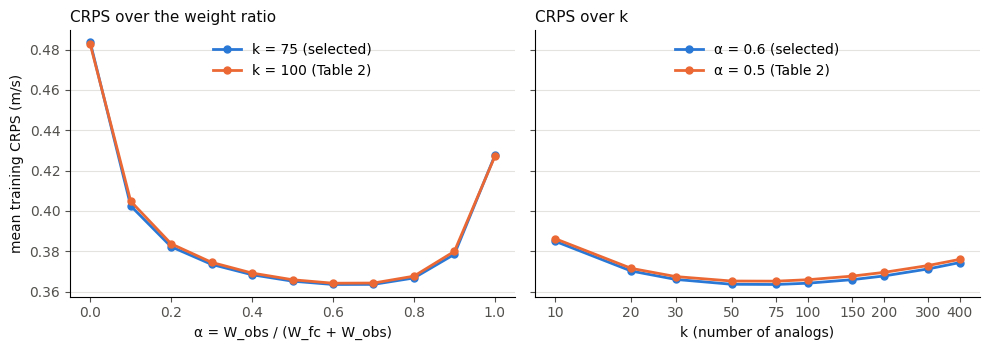

In [4]:
C_SEL, C_DEF, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)

def style(ax, xlabel):
    ax.set_xlabel(xlabel, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED)

ax = axes[0]
for k, color, label in [(k_opt, C_SEL, f"k = {k_opt} (selected)"), (100, C_DEF, "k = 100 (Table 2)")]:
    s = g.xs(k, level="k")
    ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=5, label=label)
style(ax, "α = W_obs / (W_fc + W_obs)")
ax.set_ylabel("mean training CRPS (m/s)", color=INK)
ax.set_title("CRPS over the weight ratio", color=INK, fontsize=11, loc="left")
ax.legend(frameon=False, loc="upper center")

ax = axes[1]
for a, color, label in [(a_opt, C_SEL, f"α = {a_opt} (selected)"), (0.5, C_DEF, "α = 0.5 (Table 2)")]:
    s = g.xs(a, level="alpha")
    ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=5, label=label)
style(ax, "k (number of analogs)")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(sorted(grid.k.unique()), [str(k) for k in sorted(grid.k.unique())])
ax.set_title("CRPS over k", color=INK, fontsize=11, loc="left")
ax.legend(frameon=False, loc="upper center")
plt.tight_layout()
plt.show()

## Per-location optimum

For each location the $(\alpha, k)$ with the lowest training CRPS.

In [5]:
opt_loc = train.loc[train.groupby("location")["CRPS"].idxmin(), ["location", "alpha", "k"]]
print("Number of locations per selected alpha:", opt_loc.alpha.value_counts().sort_index().to_dict())
print("Number of locations per selected k:    ", opt_loc.k.value_counts().sort_index().to_dict())

Number of locations per selected alpha: {0.5: 17, 0.6: 34, 0.7: 22, 0.8: 6, 0.9: 3}
Number of locations per selected k:     {30: 1, 50: 32, 75: 45, 100: 3, 150: 1}


## Validation period (Table 2 samples)

Mean over all locations (m/s). For each variant, $\alpha$ and $k$ are taken from the training targets.
- Baselines are taken from `baselines/baselines_metrics.csv`.
- A2E variants: Bias, CRPS and SCRPS from Table 2, RMSE of the ensemble mean from `rmse/`.
- The SCRPS is not defined for point forecasts and is unbounded for the PeEn (samples with zero spread).

In [6]:
def at(alpha, k):
    return val.xs((alpha, k), level=("alpha", "k")).mean()

rows = {}
base = pd.read_csv(EVALUATION_DIR / "baselines" / "baselines_metrics.csv", index_col=0, header=[0, 1])
k_peen = int(pd.read_csv(EVALUATION_DIR / "baselines" / "peen_k_selection.csv", index_col=0)["CRPS_train"].idxmin())
for name, col in [("Raw NWP", "NWP"), ("Persistence", "Persistence"), (f"PeEn (k={k_peen})", "PeEn")]:
    rows[name] = base.xs(col, axis=1, level=1).mean()[M]
    rows[name]["SCRPS"] = np.nan
k_only = g.xs(0.5, level="alpha").idxmin()
a_only = g.xs(100, level="k").idxmin()
k_fc = g.xs(0.0, level="alpha").idxmin()
k_ob = g.xs(1.0, level="alpha").idxmin()
rows["AnEn, Table 2 (α=0.5, k=100)"] = at(0.5, 100)
rows[f"AnEn, k optimised (α=0.5, k={k_only})"] = at(0.5, k_only)
rows[f"AnEn, α optimised (α={a_only}, k=100)"] = at(a_only, 100)
rows[f"AnEn, α and k optimised (α={a_opt}, k={k_opt})"] = at(a_opt, k_opt)
rows["AnEn, α and k optimised per location"] = val.loc[list(zip(opt_loc.location, opt_loc.alpha, opt_loc.k))].mean()
rows[f"AnEn, forecast only (α=0, k={k_fc})"] = at(0.0, k_fc)
rows[f"AnEn, observations only (α=1, k={k_ob})"] = at(1.0, k_ob)
for m in ["A2E", "CA2E", "SA2E"]:
    r = table2.xs(m, axis=1, level=1).mean()
    r["RMSE"] = pd.read_csv(EVALUATION_DIR / "rmse" / f"rmse_{m}.csv")["RMSE_new"].mean()
    rows[m] = r[M]
results = pd.DataFrame(rows).T[M]
results.round(4)

,Bias,RMSE,CRPS,SCRPS
Raw NWP,-0.2762,0.9901,0.7752,NaN
Persistence,-0.0004,0.7635,0.5618,NaN
PeEn (k=2),-0.0005,0.8185,0.5410,NaN
"AnEn, Table 2 (α=0.5, k=100)",-0.0150,0.6185,0.3373,0.7930
"AnEn, k optimised (α=0.5, k=75)",-0.0147,0.6170,0.3368,0.7931
"AnEn, α optimised (α=0.6, k=100)",-0.0128,0.6172,0.3361,0.7913
"AnEn, α and k optimised (α=0.6, k=75)",-0.0126,0.6157,0.3357,0.7912
"AnEn, α and k optimised per location",-0.0121,0.6155,0.3358,0.7918
"AnEn, forecast only (α=0, k=200)",-0.0135,0.8139,0.4534,0.9448
"AnEn, observations only (α=1, k=100)",0.0567,0.7420,0.4004,0.8806


Number of locations (of 82) at which an AnEn variant has a lower CRPS than the A2E variants:

In [7]:
crps_val = {
    "AnEn, Table 2": val.xs((0.5, 100), level=("alpha", "k"))["CRPS"].sort_index(),
    f"AnEn, α={a_opt}, k={k_opt}": val.xs((a_opt, k_opt), level=("alpha", "k"))["CRPS"].sort_index(),
    "AnEn, per location": val.loc[list(zip(opt_loc.location, opt_loc.alpha, opt_loc.k))]["CRPS"].droplevel([1, 2]).sort_index(),
}
pd.DataFrame({name: {m: int((c.values < table2[("CRPS", m)].sort_index().values).sum()) for m in ["A2E", "CA2E", "SA2E"]}
              for name, c in crps_val.items()}).T.rename(columns=lambda m: f"vs {m}")

,vs A2E,vs CA2E,vs SA2E
"AnEn, Table 2",8,4,9
"AnEn, α=0.6, k=75",10,6,9
"AnEn, per location",10,5,8
